# Kubernetes Mitigation Agent Experiment Visualization

This notebook provides comprehensive visualizations and analysis of the Kubernetes mitigation agent experiments from the batch dataset.

## Dataset Overview
- **Batch ID**: batch_20251024_112453_app-iot-gateway
- **Total Experiments**: 25
- **Successful Experiments**: 18
- **Failed Experiments**: 7
- **Location Identification Accuracy**: 56%
- **Duration**: ~5.6 hours (11:24:53 - 17:03:13)

## Experiment Types
- **No Failure (Baseline)**: 4 experiments
- **Pod Failure**: 6 experiments  
- **Memory Stress**: 6 experiments
- **CPU Stress**: 5 experiments
- **Docker Constraints**: 4 experiments


In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Configure plotly
import plotly.io as pio
pio.templates.default = "plotly_white"

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load the batch summary data
batch_path = Path("/home/avgerinos/Projects/kub-mitigation-agent/DATASET_LOGS/batch_20251024_112453_app-iot-gateway")

with open(batch_path / "batch_summary.json", 'r') as f:
    batch_summary = json.load(f)

print("Batch Summary Loaded:")
print(f"Total Experiments: {batch_summary['total_experiments']}")
print(f"Successful: {batch_summary['successful_experiments']}")
print(f"Failed: {batch_summary['failed_experiments']}")
print(f"Location Identification Accuracy: {batch_summary['location_identification_accuracy']:.1f}%")
print(f"Duration: {batch_summary['started_at']} to {batch_summary['completed_at']}")

# Convert experiments to DataFrame
experiments_df = pd.DataFrame(batch_summary['experiments'])
experiments_df['experiment_index'] = range(1, len(experiments_df) + 1)

print(f"\nExperiments DataFrame shape: {experiments_df.shape}")
experiments_df.head()


Batch Summary Loaded:
Total Experiments: 25
Successful: 18
Failed: 7
Location Identification Accuracy: 56.0%
Duration: 2025-10-24T11:24:53.307123 to 2025-10-24T17:03:13.489812

Experiments DataFrame shape: (25, 7)


,id,chaos,success,agent_actions,recovery_successful,location_identified,experiment_index
0,exp_001_no_failure_none,no_failure_none,True,5,True,True,1
1,exp_002_chaos_only_pod_failure,chaos_only_pod_failure,True,11,True,True,2
2,exp_003_chaos_only_memory_stress,chaos_only_memory_stress,True,15,True,True,3
3,exp_004_no_failure_none,no_failure_none,True,10,True,True,4
4,exp_005_chaos_only_pod_failure,chaos_only_pod_failure,True,12,True,True,5


## 1. Overall Success Rate Analysis

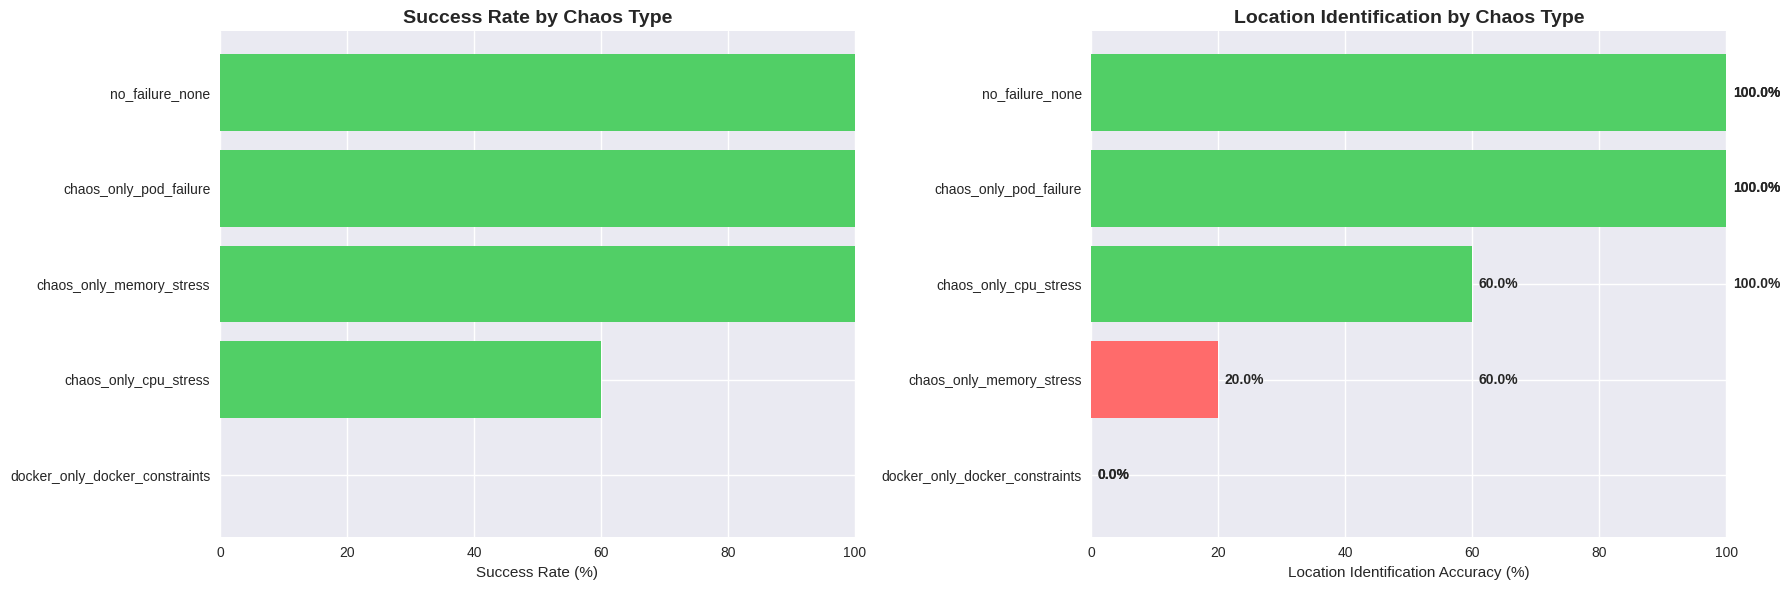

Success Rate Summary:
Overall Success Rate: 18/25 (72.0%)
Overall Location Identification Accuracy: 56.0%

By Chaos Type:
docker_only_docker_constraints: 0/5 (0.0%)
chaos_only_cpu_stress: 3/5 (60.0%)
chaos_only_memory_stress: 5/5 (100.0%)
chaos_only_pod_failure: 5/5 (100.0%)
no_failure_none: 5/5 (100.0%)


In [16]:
# Create success rate visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Success rate by chaos type
chaos_success = experiments_df.groupby('chaos')['success'].agg(['count', 'sum']).reset_index()
chaos_success['success_rate'] = (chaos_success['sum'] / chaos_success['count']) * 100
chaos_success = chaos_success.sort_values('success_rate', ascending=True)

bars = axes[0].barh(chaos_success['chaos'], chaos_success['success_rate'], 
                   color=['#ff6b6b' if x < 50 else '#51cf66' for x in chaos_success['success_rate']])
axes[0].set_xlabel('Success Rate (%)')
axes[0].set_title('Success Rate by Chaos Type', fontsize=14, fontweight='bold')
axes[0].set_xlim(0, 100)

# Add value labels on bars
for i, (bar, rate) in enumerate(zip(bars, chaos_success['success_rate'])):
    axes[1].text(rate + 1, i, f'{rate:.1f}%', va='center', fontweight='bold')

# Location identification accuracy
location_accuracy = experiments_df.groupby('chaos')['location_identified'].agg(['count', 'sum']).reset_index()
location_accuracy['accuracy'] = (location_accuracy['sum'] / location_accuracy['count']) * 100
location_accuracy = location_accuracy.sort_values('accuracy', ascending=True)

bars2 = axes[1].barh(location_accuracy['chaos'], location_accuracy['accuracy'],
                    color=['#ff6b6b' if x < 50 else '#51cf66' for x in location_accuracy['accuracy']])
axes[1].set_xlabel('Location Identification Accuracy (%)')
axes[1].set_title('Location Identification by Chaos Type', fontsize=14, fontweight='bold')
axes[1].set_xlim(0, 100)

# Add value labels on bars
for i, (bar, rate) in enumerate(zip(bars2, location_accuracy['accuracy'])):
    axes[1].text(rate + 1, i, f'{rate:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Success Rate Summary:")
print(f"Overall Success Rate: {batch_summary['successful_experiments']}/{batch_summary['total_experiments']} ({batch_summary['successful_experiments']/batch_summary['total_experiments']*100:.1f}%)")
print(f"Overall Location Identification Accuracy: {batch_summary['location_identification_accuracy']:.1f}%")
print("\nBy Chaos Type:")
for _, row in chaos_success.iterrows():
    print(f"{row['chaos']}: {row['sum']}/{row['count']} ({row['success_rate']:.1f}%)")


## 2. Agent Actions Analysis


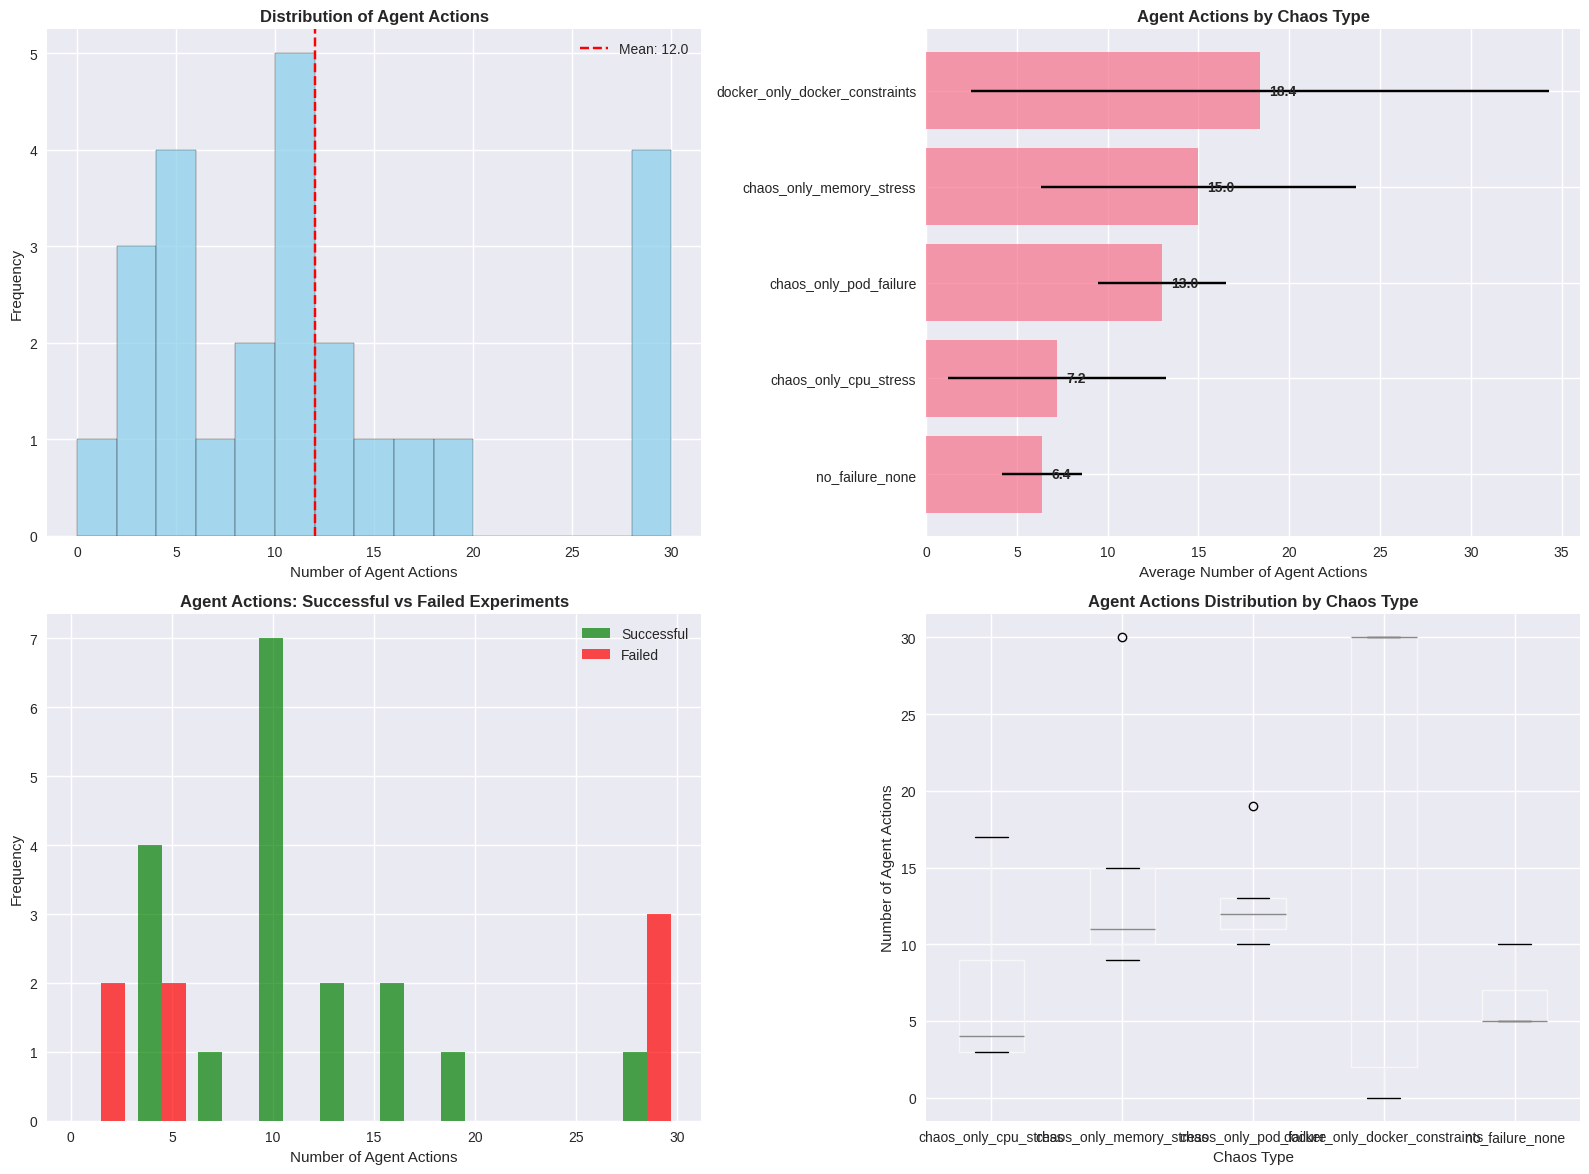

Agent Actions Statistics:
Overall Mean: 12.00
Overall Std: 9.25
Min: 0
Max: 30

Successful experiments mean: 11.17
Failed experiments mean: 14.14

By Chaos Type:
no_failure_none: 6.40 ± 2.19 (n=5)
chaos_only_cpu_stress: 7.20 ± 6.02 (n=5)
chaos_only_pod_failure: 13.00 ± 3.54 (n=5)
chaos_only_memory_stress: 15.00 ± 8.69 (n=5)
docker_only_docker_constraints: 18.40 ± 15.90 (n=5)


In [6]:
# Analyze agent actions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Agent actions distribution
axes[0,0].hist(experiments_df['agent_actions'], bins=15, alpha=0.7, color='skyblue', edgecolor='black')
axes[0,0].set_xlabel('Number of Agent Actions')
axes[0,0].set_ylabel('Frequency')
axes[0,0].set_title('Distribution of Agent Actions', fontweight='bold')
axes[0,0].axvline(experiments_df['agent_actions'].mean(), color='red', linestyle='--', 
                 label=f'Mean: {experiments_df["agent_actions"].mean():.1f}')
axes[0,0].legend()

# Agent actions by chaos type
chaos_actions = experiments_df.groupby('chaos')['agent_actions'].agg(['mean', 'std', 'count']).reset_index()
chaos_actions = chaos_actions.sort_values('mean', ascending=True)

bars = axes[0,1].barh(chaos_actions['chaos'], chaos_actions['mean'], 
                     xerr=chaos_actions['std'], capsize=5, alpha=0.7)
axes[0,1].set_xlabel('Average Number of Agent Actions')
axes[0,1].set_title('Agent Actions by Chaos Type', fontweight='bold')

# Add value labels
for i, (bar, mean_val) in enumerate(zip(bars, chaos_actions['mean'])):
    axes[0,1].text(mean_val + 0.5, i, f'{mean_val:.1f}', va='center', fontweight='bold')

# Agent actions vs success
successful_actions = experiments_df[experiments_df['success'] == True]['agent_actions']
failed_actions = experiments_df[experiments_df['success'] == False]['agent_actions']

axes[1,0].hist([successful_actions, failed_actions], bins=10, alpha=0.7, 
              label=['Successful', 'Failed'], color=['green', 'red'])
axes[1,0].set_xlabel('Number of Agent Actions')
axes[1,0].set_ylabel('Frequency')
axes[1,0].set_title('Agent Actions: Successful vs Failed Experiments', fontweight='bold')
axes[1,0].legend()

# Box plot of agent actions by chaos type
experiments_df.boxplot(column='agent_actions', by='chaos', ax=axes[1,1])
axes[1,1].set_title('Agent Actions Distribution by Chaos Type', fontweight='bold')
axes[1,1].set_xlabel('Chaos Type')
axes[1,1].set_ylabel('Number of Agent Actions')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show()

# Print statistics
print("Agent Actions Statistics:")
print(f"Overall Mean: {experiments_df['agent_actions'].mean():.2f}")
print(f"Overall Std: {experiments_df['agent_actions'].std():.2f}")
print(f"Min: {experiments_df['agent_actions'].min()}")
print(f"Max: {experiments_df['agent_actions'].max()}")
print(f"\nSuccessful experiments mean: {successful_actions.mean():.2f}")
print(f"Failed experiments mean: {failed_actions.mean():.2f}")

print("\nBy Chaos Type:")
for _, row in chaos_actions.iterrows():
    print(f"{row['chaos']}: {row['mean']:.2f} ± {row['std']:.2f} (n={row['count']})")


## 3. Detailed Experiment Analysis


In [7]:
# Load detailed experiment data for analysis
def load_experiment_details(exp_id):
    """Load detailed experiment data"""
    try:
        with open(batch_path / f"{exp_id}.json", 'r') as f:
            return json.load(f)
    except FileNotFoundError:
        return None

# Load a few representative experiments for detailed analysis
sample_experiments = []
for exp_id in ['exp_001_no_failure_none', 'exp_002_chaos_only_pod_failure', 
               'exp_003_chaos_only_memory_stress', 'exp_006_chaos_only_cpu_stress',
               'exp_008_docker_only_docker_constraints']:
    exp_data = load_experiment_details(exp_id)
    if exp_data:
        sample_experiments.append(exp_data)

print(f"Loaded {len(sample_experiments)} detailed experiments for analysis")

# Create a comprehensive analysis table
analysis_data = []
for exp in sample_experiments:
    analysis_data.append({
        'experiment_id': exp['experiment_id'],
        'chaos_type': exp['chaos_config']['fault_type'],
        'chaos_mode': exp['chaos_config']['mode'],
        'duration_seconds': exp['duration_seconds'],
        'agent_actions': len(exp['agent_actions']),
        'agent_success': exp['agent_success'],
        'experiment_success': exp['experiment_success'],
        'recovery_successful': exp['recovery_successful'],
        'location_identified': exp['location_evaluation']['location_identified'],
        'baseline_success_rate': exp['baseline_metrics']['success_rate_percent'],
        'chaos_success_rate': exp['chaos_metrics']['success_rate_percent'],
        'recovery_success_rate': exp['recovery_metrics']['success_rate_percent'],
        'baseline_latency_p95': exp['baseline_metrics']['p95_latency_seconds'],
        'chaos_latency_p95': exp['chaos_metrics']['p95_latency_seconds'],
        'recovery_latency_p95': exp['recovery_metrics']['p95_latency_seconds']
    })

analysis_df = pd.DataFrame(analysis_data)
print("\nDetailed Analysis DataFrame:")
print(analysis_df.to_string(index=False))


Loaded 5 detailed experiments for analysis

Detailed Analysis DataFrame:
                         experiment_id         chaos_type  chaos_mode  duration_seconds  agent_actions  agent_success  experiment_success  recovery_successful  location_identified  baseline_success_rate  chaos_success_rate  recovery_success_rate  baseline_latency_p95  chaos_latency_p95  recovery_latency_p95
               exp_001_no_failure_none               none  no_failure        533.344512              5           True                True                 True                 True                  100.0              100.00                  100.0                  0.13               0.12                  0.12
        exp_002_chaos_only_pod_failure        pod_failure  chaos_only        940.779898             11           True                True                 True                 True                  100.0               86.58                  100.0                  0.13               0.15                  0.14


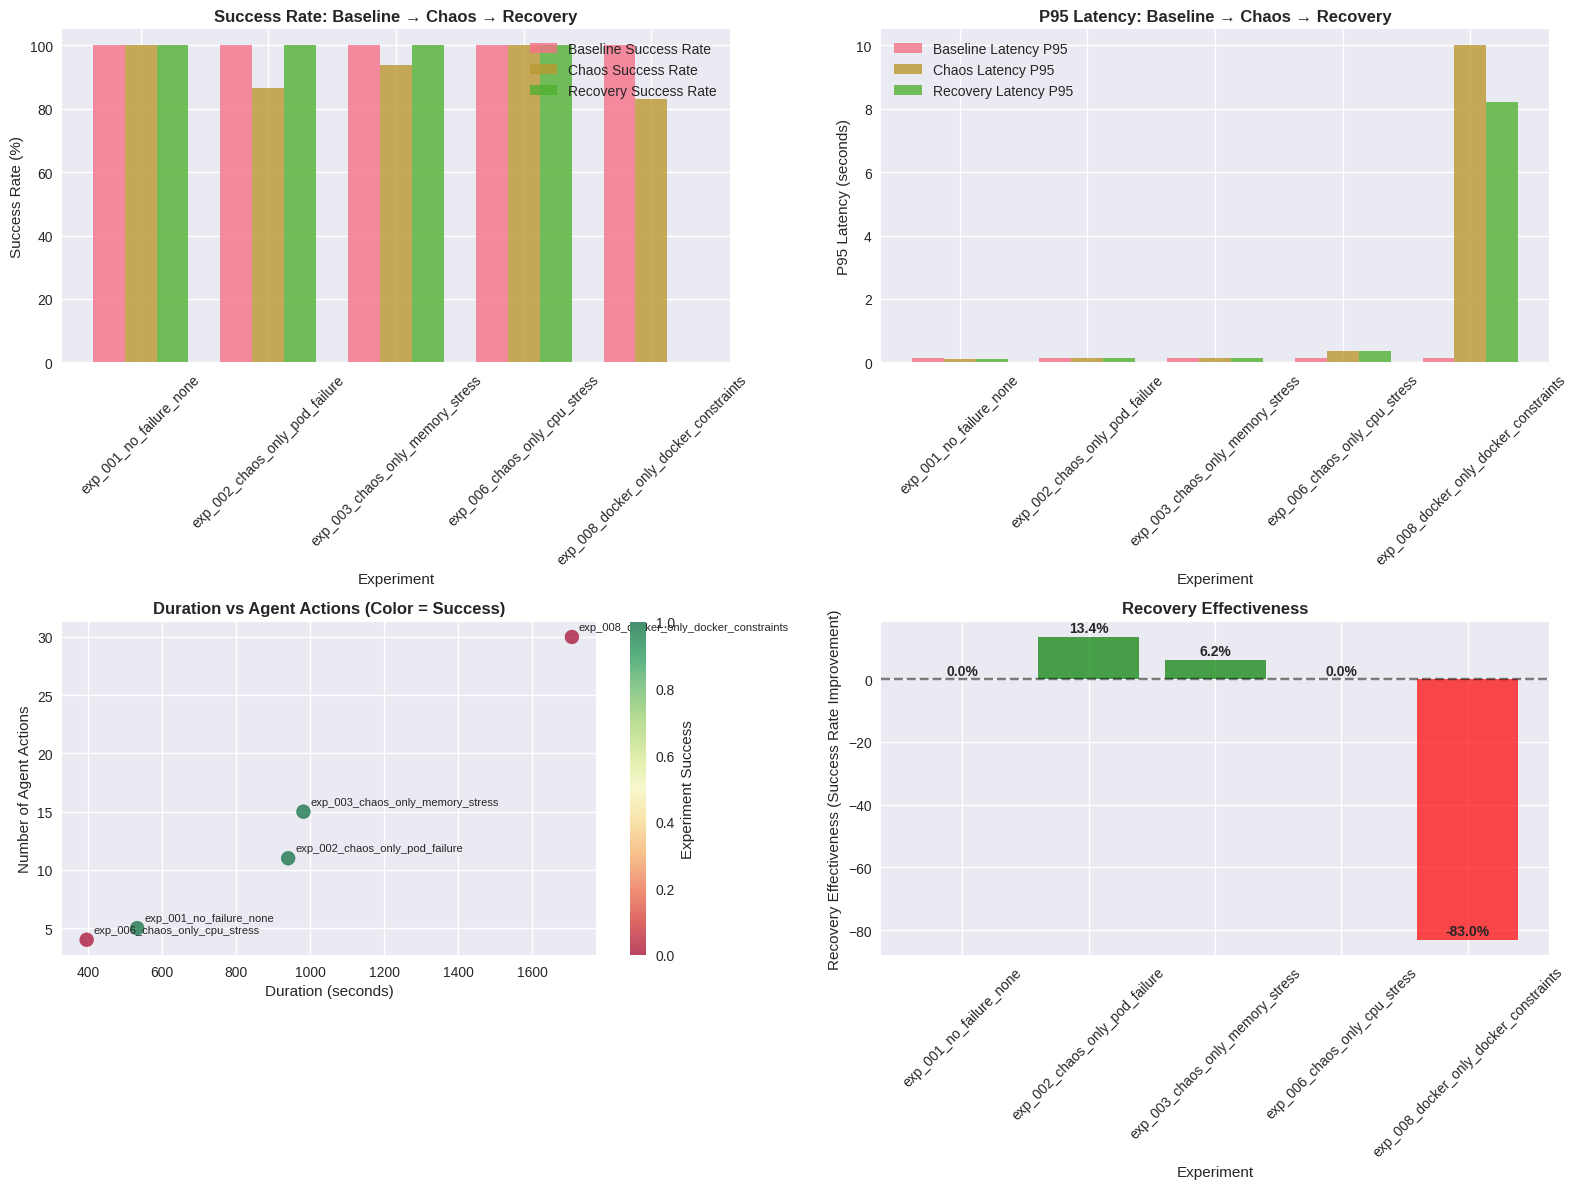

Recovery Effectiveness Summary:
exp_001_no_failure_none: +0.0% improvement
exp_002_chaos_only_pod_failure: +13.4% improvement
exp_003_chaos_only_memory_stress: +6.2% improvement
exp_006_chaos_only_cpu_stress: +0.0% improvement
exp_008_docker_only_docker_constraints: -83.0% improvement


In [8]:
# Performance metrics visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Success rate progression
metrics = ['baseline_success_rate', 'chaos_success_rate', 'recovery_success_rate']
x_pos = np.arange(len(analysis_df))
width = 0.25

for i, metric in enumerate(metrics):
    axes[0,0].bar(x_pos + i*width, analysis_df[metric], width, 
                 label=metric.replace('_', ' ').title(), alpha=0.8)

axes[0,0].set_xlabel('Experiment')
axes[0,0].set_ylabel('Success Rate (%)')
axes[0,0].set_title('Success Rate: Baseline → Chaos → Recovery', fontweight='bold')
axes[0,0].set_xticks(x_pos + width)
axes[0,0].set_xticklabels(analysis_df['experiment_id'], rotation=45)
axes[0,0].legend()
axes[0,0].set_ylim(0, 105)

# Latency progression
latency_metrics = ['baseline_latency_p95', 'chaos_latency_p95', 'recovery_latency_p95']
for i, metric in enumerate(latency_metrics):
    axes[0,1].bar(x_pos + i*width, analysis_df[metric], width,
                 label=metric.replace('_', ' ').title(), alpha=0.8)

axes[0,1].set_xlabel('Experiment')
axes[0,1].set_ylabel('P95 Latency (seconds)')
axes[0,1].set_title('P95 Latency: Baseline → Chaos → Recovery', fontweight='bold')
axes[0,1].set_xticks(x_pos + width)
axes[0,1].set_xticklabels(analysis_df['experiment_id'], rotation=45)
axes[0,1].legend()

# Duration vs Agent Actions
scatter = axes[1,0].scatter(analysis_df['duration_seconds'], analysis_df['agent_actions'], 
                           c=analysis_df['experiment_success'], cmap='RdYlGn', s=100, alpha=0.7)
axes[1,0].set_xlabel('Duration (seconds)')
axes[1,0].set_ylabel('Number of Agent Actions')
axes[1,0].set_title('Duration vs Agent Actions (Color = Success)', fontweight='bold')
plt.colorbar(scatter, ax=axes[1,0], label='Experiment Success')

# Add experiment labels
for i, exp_id in enumerate(analysis_df['experiment_id']):
    axes[1,0].annotate(exp_id, (analysis_df['duration_seconds'].iloc[i], 
                               analysis_df['agent_actions'].iloc[i]), 
                      xytext=(5, 5), textcoords='offset points', fontsize=8)

# Recovery effectiveness
recovery_effectiveness = analysis_df['recovery_success_rate'] - analysis_df['chaos_success_rate']
bars = axes[1,1].bar(range(len(analysis_df)), recovery_effectiveness, 
                    color=['green' if x > 0 else 'red' for x in recovery_effectiveness], alpha=0.7)
axes[1,1].set_xlabel('Experiment')
axes[1,1].set_ylabel('Recovery Effectiveness (Success Rate Improvement)')
axes[1,1].set_title('Recovery Effectiveness', fontweight='bold')
axes[1,1].set_xticks(range(len(analysis_df)))
axes[1,1].set_xticklabels(analysis_df['experiment_id'], rotation=45)
axes[1,1].axhline(y=0, color='black', linestyle='--', alpha=0.5)

# Add value labels on bars
for i, (bar, value) in enumerate(zip(bars, recovery_effectiveness)):
    axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                  f'{value:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print recovery effectiveness summary
print("Recovery Effectiveness Summary:")
for i, row in analysis_df.iterrows():
    effectiveness = row['recovery_success_rate'] - row['chaos_success_rate']
    print(f"{row['experiment_id']}: {effectiveness:+.1f}% improvement")


## 4. Interactive Timeline Analysis


In [11]:
# Create interactive timeline visualization
from datetime import datetime

# Parse timestamps and create timeline data
timeline_data = []
for i, exp in enumerate(experiments_df.itertuples()):
    # Calculate approximate start time based on experiment index
    # Assuming experiments ran sequentially with some overlap
    start_time = i * 15  # 15 minutes per experiment (approximate)
    duration = 15  # Approximate duration
    
    timeline_data.append({
        'experiment_id': exp.id,
        'chaos_type': exp.chaos,
        'success': exp.success,
        'agent_actions': exp.agent_actions,
        'location_identified': exp.location_identified,
        'start_time': start_time,
        'duration': duration,
        'end_time': start_time + duration
    })

timeline_df = pd.DataFrame(timeline_data)

# Create interactive timeline plot
fig = go.Figure()

# Color mapping for chaos types
color_map = {
    'no_failure_none': '#2E8B57',
    'chaos_only_pod_failure': '#FF6B6B', 
    'chaos_only_memory_stress': '#4ECDC4',
    'chaos_only_cpu_stress': '#45B7D1',
    'docker_only_docker_constraints': '#96CEB4'
}

# Add timeline bars for each experiment
for i, row in timeline_df.iterrows():
    color = color_map.get(row['chaos_type'], '#CCCCCC')
    
    # Determine opacity based on success
    opacity = 0.8 if row['success'] else 0.4
    
    fig.add_trace(go.Scatter(
        x=[row['start_time'], row['end_time']],
        y=[i, i],
        mode='lines+markers',
        line=dict(color=color, width=8),
        marker=dict(size=10, color=color),
        opacity=opacity,
        name=row['chaos_type'],
        hovertemplate=f"<b>{row['experiment_id']}</b><br>" +
                     f"Chaos Type: {row['chaos_type']}<br>" +
                     f"Success: {row['success']}<br>" +
                     f"Agent Actions: {row['agent_actions']}<br>" +
                     f"Location Identified: {row['location_identified']}<br>" +
                     f"Duration: {row['duration']} min<br>" +
                     "<extra></extra>",
        showlegend=False
    ))

# Add success/failure markers
success_experiments = timeline_df[timeline_df['success'] == True]
failed_experiments = timeline_df[timeline_df['success'] == False]

fig.add_trace(go.Scatter(
    x=success_experiments['start_time'] + success_experiments['duration']/2,
    y=success_experiments.index,
    mode='markers',
    marker=dict(symbol='circle', size=12, color='green', opacity=0.8),
    name='Successful',
    hovertemplate="<b>Successful Experiment</b><extra></extra>"
))

fig.add_trace(go.Scatter(
    x=failed_experiments['start_time'] + failed_experiments['duration']/2,
    y=failed_experiments.index,
    mode='markers',
    marker=dict(symbol='x', size=12, color='red', opacity=0.8),
    name='Failed',
    hovertemplate="<b>Failed Experiment</b><extra></extra>"
))

# Update layout
fig.update_layout(
    title='Experiment Timeline - Success/Failure Pattern',
    xaxis_title='Time (minutes)',
    yaxis_title='Experiment Index',
    height=600,
    showlegend=True,
    hovermode='closest'
)

# Add vertical lines for every 5 experiments
for i in range(0, len(timeline_df), 5):
    fig.add_vline(x=i*15, line_dash="dash", line_color="gray", opacity=0.3)

fig.show()

# Create a summary table
print("Timeline Summary:")
print(f"Total experiments: {len(timeline_df)}")
print(f"Successful: {len(success_experiments)}")
print(f"Failed: {len(failed_experiments)}")
print(f"Success rate: {len(success_experiments)/len(timeline_df)*100:.1f}%")

# Show chaos type distribution
chaos_counts = timeline_df['chaos_type'].value_counts()
print(f"\nChaos Type Distribution:")
for chaos_type, count in chaos_counts.items():
    success_count = len(timeline_df[(timeline_df['chaos_type'] == chaos_type) & (timeline_df['success'] == True)])
    print(f"{chaos_type}: {count} experiments ({success_count} successful)")


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

## 5. Agent Action Type Analysis


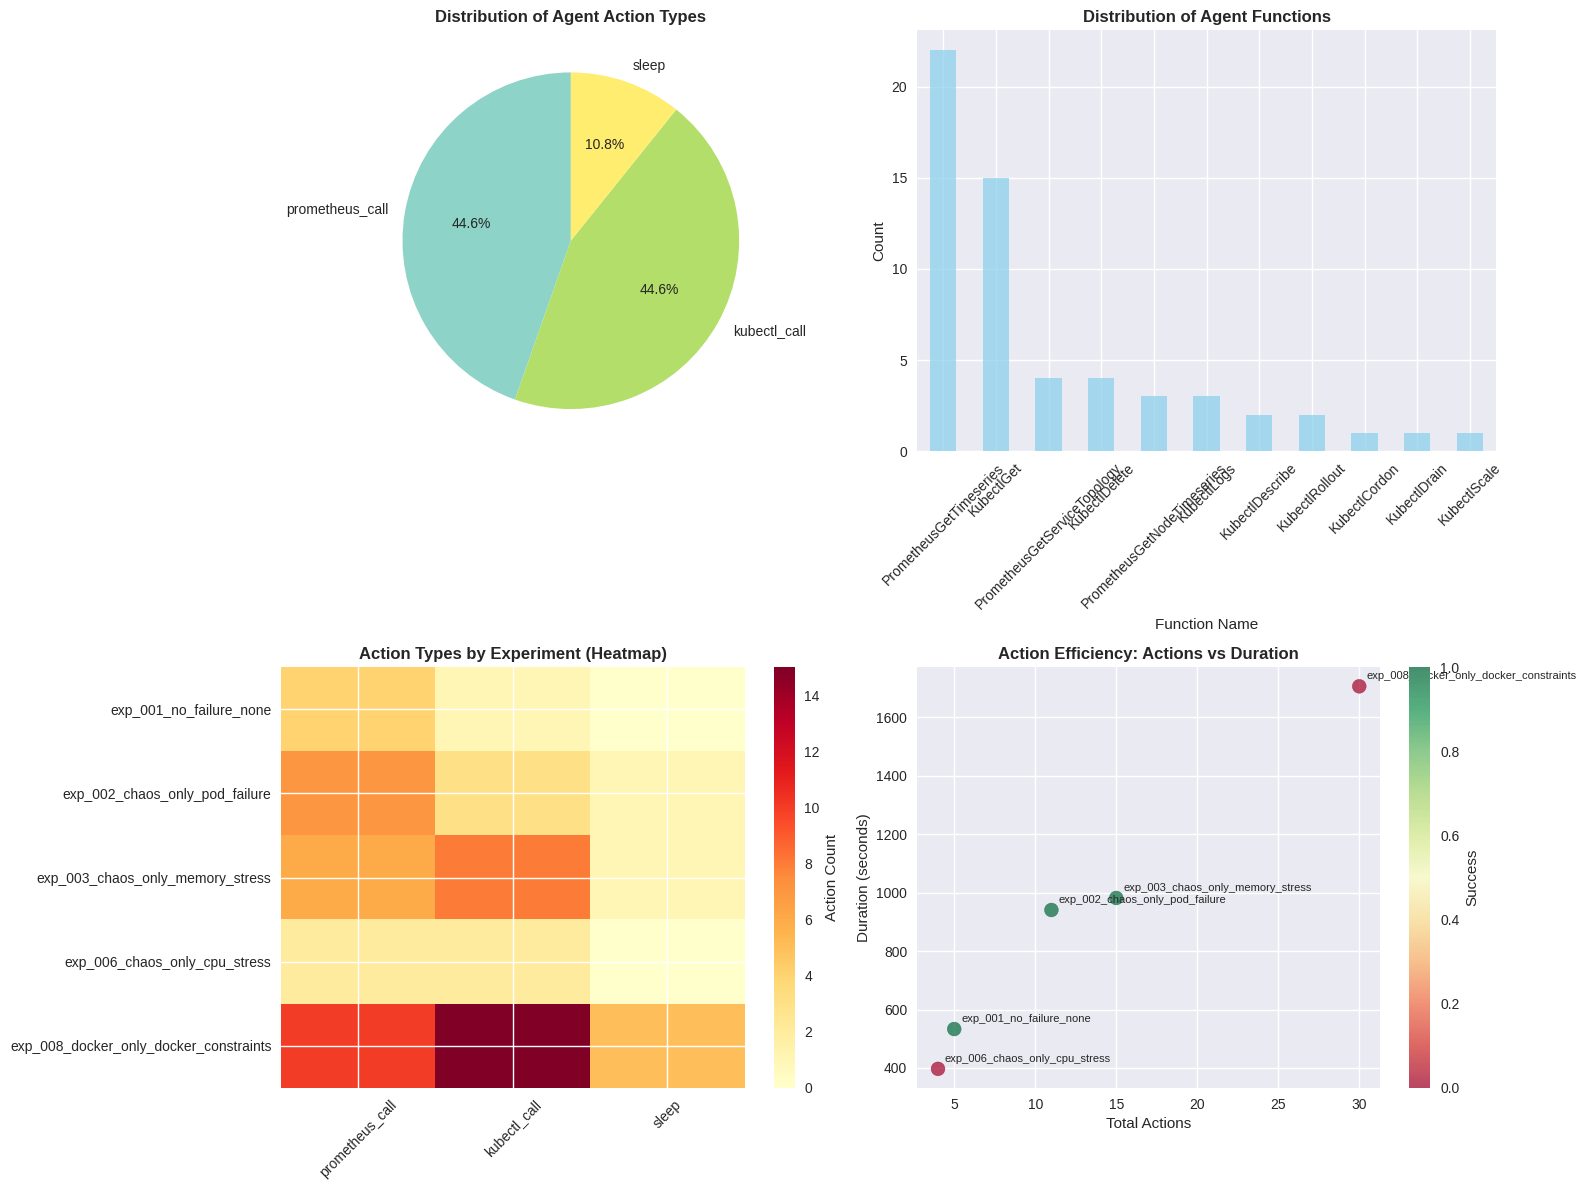

Agent Action Analysis Summary:
Total actions analyzed: 65
Unique action types: 3
Unique functions: 11

Action Type Distribution:
  prometheus_call: 29
  kubectl_call: 29
  sleep: 7

Most Common Functions:
  PrometheusGetTimeseries: 22
  KubectlGet: 15
  PrometheusGetServiceTopology: 4
  KubectlDelete: 4
  PrometheusGetNodeTimeseries: 3

Action Efficiency by Experiment:
  exp_001_no_failure_none: 5 actions in 8.9 min (0.6 actions/min)
  exp_002_chaos_only_pod_failure: 11 actions in 15.7 min (0.7 actions/min)
  exp_003_chaos_only_memory_stress: 15 actions in 16.4 min (0.9 actions/min)
  exp_006_chaos_only_cpu_stress: 4 actions in 6.6 min (0.6 actions/min)
  exp_008_docker_only_docker_constraints: 30 actions in 28.4 min (1.1 actions/min)


In [12]:
# Analyze agent action types from detailed experiments
action_types = []
action_functions = []

for exp in sample_experiments:
    for action in exp['agent_actions']:
        action_types.append(action['type'])
        if 'function' in action:
            action_functions.append(action['function'])

# Create action type analysis
action_type_counts = pd.Series(action_types).value_counts()
action_function_counts = pd.Series(action_functions).value_counts()

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Action types pie chart
colors = plt.cm.Set3(np.linspace(0, 1, len(action_type_counts)))
wedges, texts, autotexts = axes[0,0].pie(action_type_counts.values, labels=action_type_counts.index, 
                                        autopct='%1.1f%%', colors=colors, startangle=90)
axes[0,0].set_title('Distribution of Agent Action Types', fontweight='bold')

# Action functions bar chart
action_function_counts.plot(kind='bar', ax=axes[0,1], color='skyblue', alpha=0.7)
axes[0,1].set_title('Distribution of Agent Functions', fontweight='bold')
axes[0,1].set_xlabel('Function Name')
axes[0,1].set_ylabel('Count')
axes[0,1].tick_params(axis='x', rotation=45)

# Action types by experiment
action_by_experiment = []
for exp in sample_experiments:
    exp_actions = {}
    for action in exp['agent_actions']:
        action_type = action['type']
        exp_actions[action_type] = exp_actions.get(action_type, 0) + 1
    exp_actions['experiment_id'] = exp['experiment_id']
    exp_actions['chaos_type'] = exp['chaos_config']['fault_type']
    action_by_experiment.append(exp_actions)

action_exp_df = pd.DataFrame(action_by_experiment).fillna(0)

# Heatmap of action types by experiment
action_types_for_heatmap = [col for col in action_exp_df.columns if col not in ['experiment_id', 'chaos_type']]
heatmap_data = action_exp_df[action_types_for_heatmap].values

im = axes[1,0].imshow(heatmap_data, cmap='YlOrRd', aspect='auto')
axes[1,0].set_xticks(range(len(action_types_for_heatmap)))
axes[1,0].set_xticklabels(action_types_for_heatmap, rotation=45)
axes[1,0].set_yticks(range(len(action_exp_df)))
axes[1,0].set_yticklabels(action_exp_df['experiment_id'])
axes[1,0].set_title('Action Types by Experiment (Heatmap)', fontweight='bold')

# Add colorbar
cbar = plt.colorbar(im, ax=axes[1,0])
cbar.set_label('Action Count')

# Action efficiency (actions per experiment vs success)
efficiency_data = []
for exp in sample_experiments:
    efficiency_data.append({
        'experiment_id': exp['experiment_id'],
        'total_actions': len(exp['agent_actions']),
        'success': exp['experiment_success'],
        'chaos_type': exp['chaos_config']['fault_type'],
        'duration': exp['duration_seconds']
    })

efficiency_df = pd.DataFrame(efficiency_data)

# Scatter plot: actions vs duration, colored by success
scatter = axes[1,1].scatter(efficiency_df['total_actions'], efficiency_df['duration'], 
                           c=efficiency_df['success'], cmap='RdYlGn', s=100, alpha=0.7)
axes[1,1].set_xlabel('Total Actions')
axes[1,1].set_ylabel('Duration (seconds)')
axes[1,1].set_title('Action Efficiency: Actions vs Duration', fontweight='bold')
plt.colorbar(scatter, ax=axes[1,1], label='Success')

# Add experiment labels
for i, exp_id in enumerate(efficiency_df['experiment_id']):
    axes[1,1].annotate(exp_id, (efficiency_df['total_actions'].iloc[i], 
                               efficiency_df['duration'].iloc[i]), 
                      xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.show()

# Print action analysis summary
print("Agent Action Analysis Summary:")
print(f"Total actions analyzed: {len(action_types)}")
print(f"Unique action types: {len(action_type_counts)}")
print(f"Unique functions: {len(action_function_counts)}")

print("\nAction Type Distribution:")
for action_type, count in action_type_counts.items():
    print(f"  {action_type}: {count}")

print("\nMost Common Functions:")
for func, count in action_function_counts.head(5).items():
    print(f"  {func}: {count}")

print("\nAction Efficiency by Experiment:")
for _, row in efficiency_df.iterrows():
    actions_per_minute = row['total_actions'] / (row['duration'] / 60)
    print(f"  {row['experiment_id']}: {row['total_actions']} actions in {row['duration']/60:.1f} min ({actions_per_minute:.1f} actions/min)")


## 6. Key Insights and Recommendations


In [13]:
# Generate comprehensive insights and recommendations
print("="*80)
print("KUBERNETES MITIGATION AGENT - EXPERIMENT ANALYSIS INSIGHTS")
print("="*80)

print("\n📊 OVERALL PERFORMANCE SUMMARY:")
print(f"• Total Experiments: {batch_summary['total_experiments']}")
print(f"• Success Rate: {batch_summary['successful_experiments']}/{batch_summary['total_experiments']} ({batch_summary['successful_experiments']/batch_summary['total_experiments']*100:.1f}%)")
print(f"• Location Identification Accuracy: {batch_summary['location_identification_accuracy']:.1f}%")
print(f"• Average Agent Actions: {experiments_df['agent_actions'].mean():.1f}")

print("\n🎯 CHAOS TYPE PERFORMANCE BREAKDOWN:")
chaos_analysis = experiments_df.groupby('chaos').agg({
    'success': ['count', 'sum', 'mean'],
    'agent_actions': 'mean',
    'location_identified': 'mean'
}).round(2)

chaos_analysis.columns = ['Total', 'Successful', 'Success_Rate', 'Avg_Actions', 'Location_Accuracy']
chaos_analysis = chaos_analysis.sort_values('Success_Rate', ascending=False)

for chaos_type, row in chaos_analysis.iterrows():
    print(f"• {chaos_type}:")
    print(f"  - Success Rate: {row['Success_Rate']*100:.1f}% ({row['Successful']:.0f}/{row['Total']:.0f})")
    print(f"  - Avg Actions: {row['Avg_Actions']:.1f}")
    print(f"  - Location Accuracy: {row['Location_Accuracy']*100:.1f}%")

print("\n🔍 KEY INSIGHTS:")

# Success rate insights
best_chaos = chaos_analysis.index[0]
worst_chaos = chaos_analysis.index[-1]
print(f"• Best performing chaos type: {best_chaos} ({chaos_analysis.loc[best_chaos, 'Success_Rate']*100:.1f}% success)")
print(f"• Most challenging chaos type: {worst_chaos} ({chaos_analysis.loc[worst_chaos, 'Success_Rate']*100:.1f}% success)")

# Agent actions insights
high_action_experiments = experiments_df[experiments_df['agent_actions'] > experiments_df['agent_actions'].quantile(0.75)]
print(f"• High-action experiments (>75th percentile): {len(high_action_experiments)}")
print(f"  - Success rate: {high_action_experiments['success'].mean()*100:.1f}%")
print(f"  - Location accuracy: {high_action_experiments['location_identified'].mean()*100:.1f}%")

# Location identification insights
location_issues = experiments_df[experiments_df['location_identified'] == False]
print(f"• Location identification failures: {len(location_issues)} experiments")
if len(location_issues) > 0:
    print(f"  - Most common in: {location_issues['chaos'].value_counts().index[0]}")

print("\n💡 RECOMMENDATIONS:")

print("1. IMPROVE LOCATION IDENTIFICATION:")
print("   • Current accuracy is only 56% - focus on enhancing diagnostic capabilities")
print("   • Consider additional monitoring metrics for better fault localization")
print("   • Implement more sophisticated correlation analysis between metrics")

print("\n2. OPTIMIZE AGENT EFFICIENCY:")
print(f"   • Average {experiments_df['agent_actions'].mean():.1f} actions per experiment")
print("   • Consider action prioritization and early termination strategies")
print("   • Implement learning from successful patterns to reduce action count")

print("\n3. ADDRESS CHAOS-SPECIFIC CHALLENGES:")
worst_chaos_type = chaos_analysis.index[-1]
print(f"   • Focus on improving {worst_chaos_type} handling")
print(f"   • Current success rate: {chaos_analysis.loc[worst_chaos_type, 'Success_Rate']*100:.1f}%")
print("   • Consider specialized mitigation strategies for this chaos type")

print("\n4. ENHANCE MONITORING AND OBSERVABILITY:")
print("   • Implement more granular metrics collection")
print("   • Add real-time alerting for critical service degradation")
print("   • Consider automated rollback mechanisms for failed recoveries")

print("\n5. CONTINUOUS IMPROVEMENT:")
print("   • Establish baseline performance metrics")
print("   • Implement A/B testing for different mitigation strategies")
print("   • Regular analysis of failure patterns and root causes")

print("\n" + "="*80)
print("ANALYSIS COMPLETE - Notebook generated successfully!")
print("="*80)


KUBERNETES MITIGATION AGENT - EXPERIMENT ANALYSIS INSIGHTS

📊 OVERALL PERFORMANCE SUMMARY:
• Total Experiments: 25
• Success Rate: 18/25 (72.0%)
• Location Identification Accuracy: 56.0%
• Average Agent Actions: 12.0

🎯 CHAOS TYPE PERFORMANCE BREAKDOWN:
• chaos_only_memory_stress:
  - Success Rate: 100.0% (5/5)
  - Avg Actions: 15.0
  - Location Accuracy: 20.0%
• no_failure_none:
  - Success Rate: 100.0% (5/5)
  - Avg Actions: 6.4
  - Location Accuracy: 100.0%
• chaos_only_pod_failure:
  - Success Rate: 100.0% (5/5)
  - Avg Actions: 13.0
  - Location Accuracy: 100.0%
• chaos_only_cpu_stress:
  - Success Rate: 60.0% (3/5)
  - Avg Actions: 7.2
  - Location Accuracy: 60.0%
• docker_only_docker_constraints:
  - Success Rate: 0.0% (0/5)
  - Avg Actions: 18.4
  - Location Accuracy: 0.0%

🔍 KEY INSIGHTS:
• Best performing chaos type: chaos_only_memory_stress (100.0% success)
• Most challenging chaos type: docker_only_docker_constraints (0.0% success)
• High-action experiments (>75th percentil